# Movie Recommender System: EDA and Matrix Factorization

Exploratory analysis of MovieLens 1M followed by the SVD / PMF results.
Run `python train.py` once from the project root before executing the results sections.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from utils.data_loader import build_index, encode, load_movies, load_ratings, load_users, split_ratings
from utils.matrix_creation import center, to_csr, user_means

plt.rcParams["figure.figsize"] = (8, 4.5)

## 1. Loading and cleaning

In [2]:
ratings = load_ratings()
movies = load_movies()
users = load_users()

print("Null values per table:")
print(ratings.isna().sum().to_dict(), movies.isna().sum().to_dict(), users.isna().sum().to_dict())
print("Duplicate (user, movie) pairs:", ratings.duplicated(["user_id", "movie_id"]).sum())
display(ratings.head())

Null values per table:
{'user_id': 0, 'movie_id': 0, 'rating': 0, 'timestamp': 0} {'movie_id': 0, 'title': 0, 'genres': 0} {'user_id': 0, 'gender': 0, 'age': 0, 'occupation': 0, 'zip_code': 0}
Duplicate (user, movie) pairs: 0


,user_id,movie_id,rating,timestamp
0,1,1193,5.0,978300760
1,1,661,3.0,978302109
2,1,914,3.0,978301968
3,1,3408,4.0,978300275
4,1,2355,5.0,978824291


## 2. Dataset overview

In [3]:
n_users, n_movies, n_ratings = ratings.user_id.nunique(), ratings.movie_id.nunique(), len(ratings)
density = n_ratings / (n_users * n_movies)
print(f"users={n_users}  rated movies={n_movies}  ratings={n_ratings}")
print(f"matrix density={density:.2%}  sparsity={1 - density:.2%}")
print(f"mean rating={ratings.rating.mean():.3f}  median={ratings.rating.median():.1f}")

users=6040  rated movies=3706  ratings=1000209
matrix density=4.47%  sparsity=95.53%
mean rating=3.582  median=4.0


## 3. Rating distribution

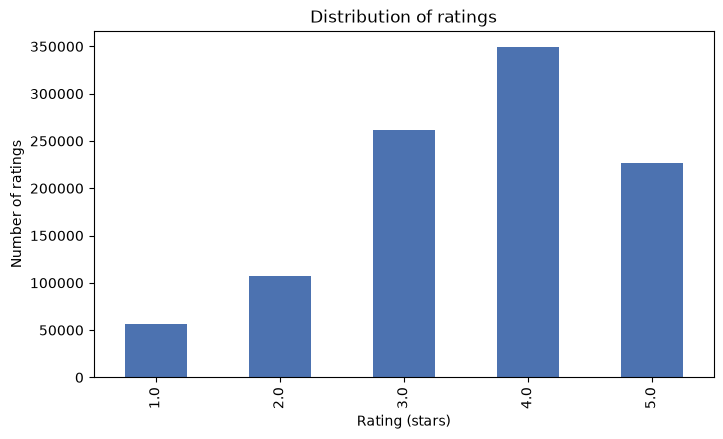

{1.0: 0.056, 2.0: 0.108, 3.0: 0.261, 4.0: 0.349, 5.0: 0.226}


In [4]:
dist = ratings.rating.value_counts().sort_index()
ax = dist.plot.bar(color="#4C72B0")
ax.set_title("Distribution of ratings")
ax.set_xlabel("Rating (stars)")
ax.set_ylabel("Number of ratings")
plt.show()
print((dist / dist.sum()).round(3).to_dict())

## 4. Activity per user and popularity per movie

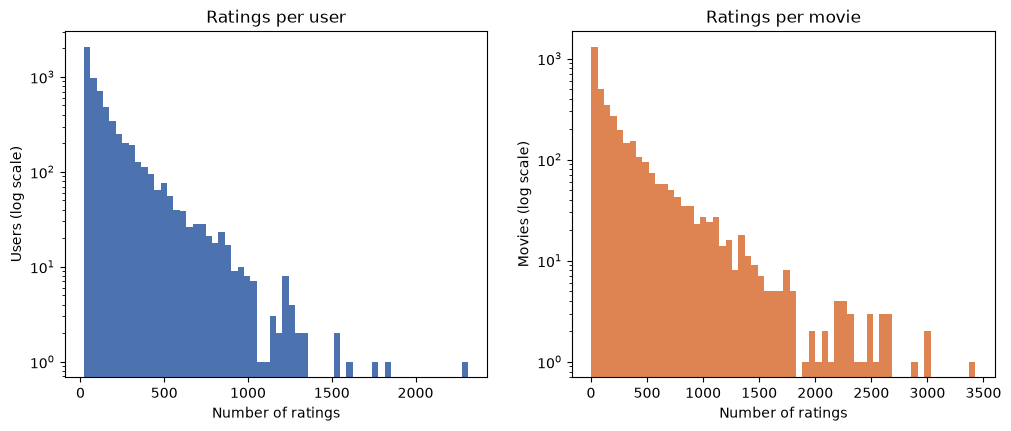

{'count': 6040.0, 'mean': 165.6, 'std': 192.7, 'min': 20.0, '25%': 44.0, '50%': 96.0, '75%': 208.0, 'max': 2314.0}
{'count': 3706.0, 'mean': 269.9, 'std': 384.0, 'min': 1.0, '25%': 33.0, '50%': 123.5, '75%': 350.0, 'max': 3428.0}
Share of ratings on the top 10% most-rated movies: 0.444


In [5]:
per_user = ratings.groupby("user_id").size()
per_movie = ratings.groupby("movie_id").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(per_user, bins=60, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Users (log scale)")
axes[1].hist(per_movie, bins=60, color="#DD8452")
axes[1].set_yscale("log")
axes[1].set_title("Ratings per movie")
axes[1].set_xlabel("Number of ratings")
axes[1].set_ylabel("Movies (log scale)")
plt.show()
print(per_user.describe().round(1).to_dict())
print(per_movie.describe().round(1).to_dict())
print("Share of ratings on the top 10% most-rated movies:",
      round(per_movie.sort_values(ascending=False).head(int(len(per_movie) * 0.1)).sum() / len(ratings), 3))

## 5. Genres

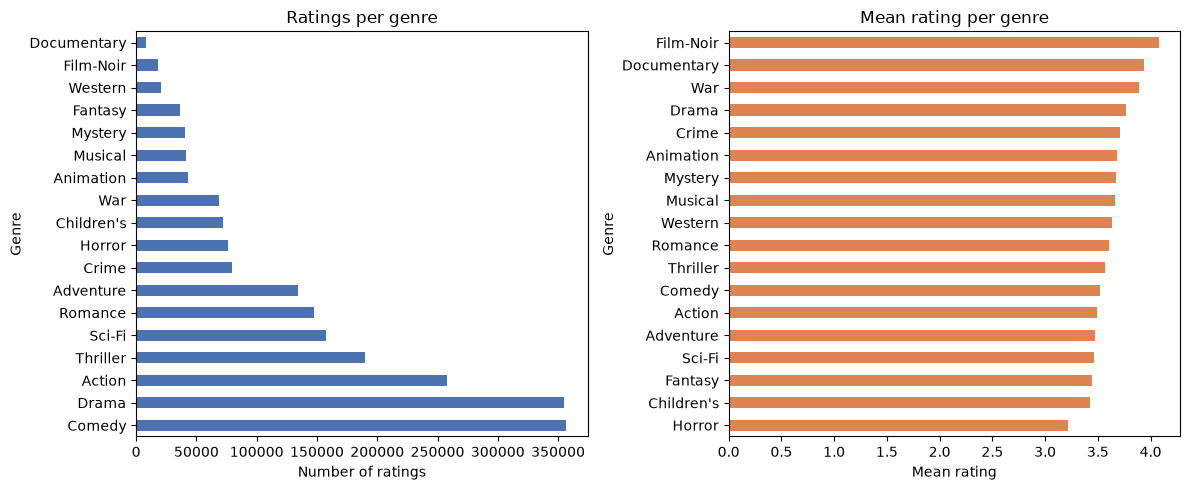

In [6]:
data = ratings.merge(movies, on="movie_id")
genre_rows = data.assign(genre=data.genres.str.split("|")).explode("genre")
stats = genre_rows.groupby("genre").rating.agg(["count", "mean"]).sort_values("count", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
stats["count"].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Ratings per genre")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Genre")
stats["mean"].sort_values().plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Mean rating per genre")
axes[1].set_xlabel("Mean rating")
axes[1].set_ylabel("Genre")
plt.tight_layout()
plt.show()

## 6. Demographics and time

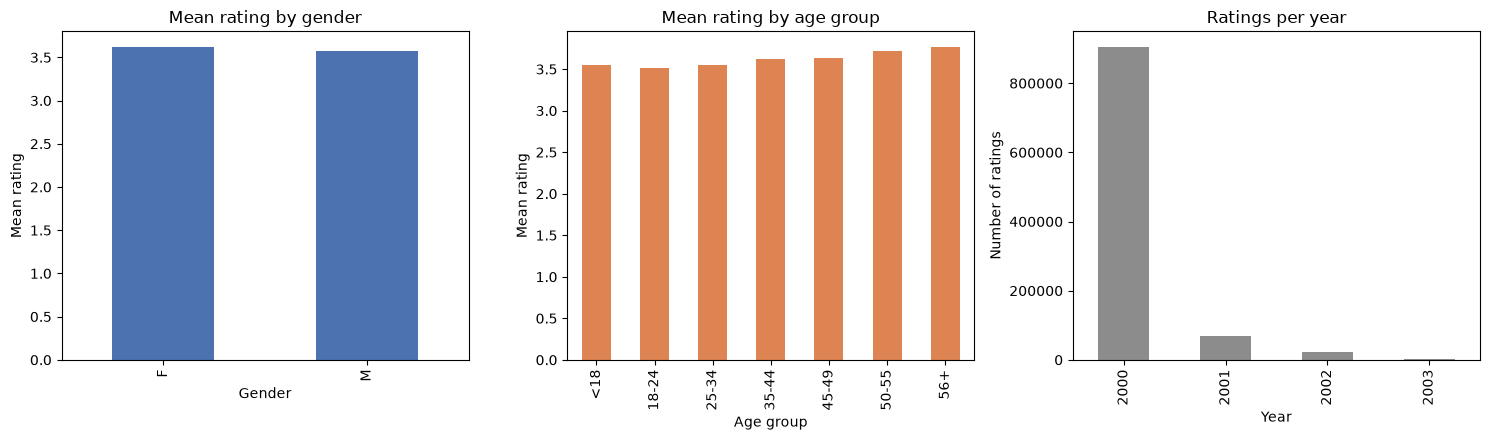

In [7]:
joined = ratings.merge(users, on="user_id")
age_labels = {1: "<18", 18: "18-24", 25: "25-34", 35: "35-44", 45: "45-49", 50: "50-55", 56: "56+"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
joined.groupby("gender").rating.mean().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Mean rating by gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Mean rating")
joined.groupby("age").rating.mean().rename(index=age_labels).plot.bar(ax=axes[1], color="#DD8452")
axes[1].set_title("Mean rating by age group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Mean rating")
year = pd.to_datetime(ratings.timestamp, unit="s").dt.year.value_counts().sort_index()
year.plot.bar(ax=axes[2], color="#8C8C8C")
axes[2].set_title("Ratings per year")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Number of ratings")
plt.tight_layout()
plt.show()

## 7. Split and normalized user-item matrix

In [8]:
user_ids, movie_ids = build_index(ratings)
encoded = encode(ratings, user_ids, movie_ids)
train, test = split_ratings(encoded, test_size=0.2, random_state=42)
R_train = to_csr(train, len(user_ids), len(movie_ids))
means = user_means(R_train)
Rc = center(R_train, means)
print(f"train={len(train)} test={len(test)} (random_state=42)")
print(f"train matrix shape={R_train.shape} density={R_train.nnz / np.prod(R_train.shape):.2%}")
print("Centered ratings: mean=%.4f std=%.3f" % (Rc.data.mean(), Rc.data.std()))

train=800168 test=200041 (random_state=42)
train matrix shape=(6040, 3706) density=3.57%
Centered ratings: mean=0.0000 std=1.027


## 8. Model results (after `python train.py`)

{'SVD_RMSE': 0.9633, 'PMF_RMSE': 0.868, 'PMF_vs_SVD_improvement_%': 9.9}
Item-kNN benchmark RMSE: 0.9307 | matrix factorization beats it: False
Thresholds: {'SVD_RMSE<=0.90': False, 'PMF_RMSE<=0.85': False, 'improvement>=5%': True}


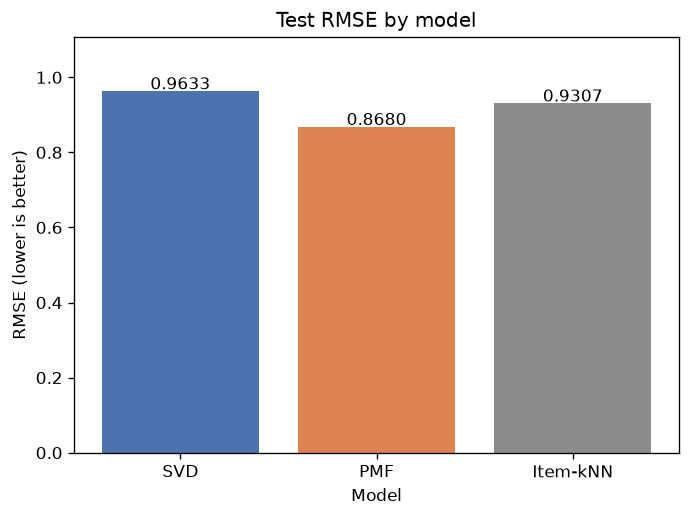

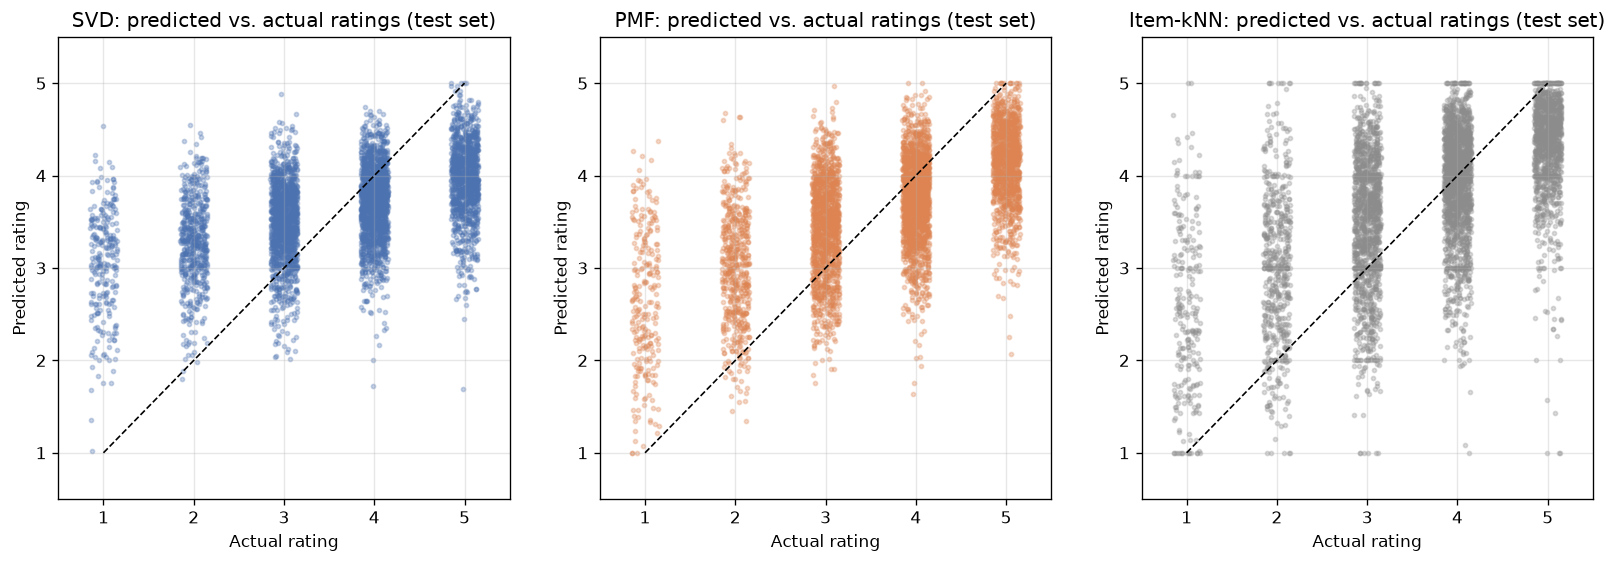

In [9]:
reports = ROOT / "reports"
metrics = json.loads((reports / "model_metrics.json").read_text())
extra = json.loads((reports / "extra_metrics.json").read_text())
print(metrics)
print("Item-kNN benchmark RMSE:", extra["KNN_RMSE"], "| matrix factorization beats it:", extra["mf_beats_knn"])
print("Thresholds:", extra["thresholds_met"])
display(Image(str(reports / "rmse_comparison.png")))
display(Image(str(reports / "predicted_vs_actual.png")))

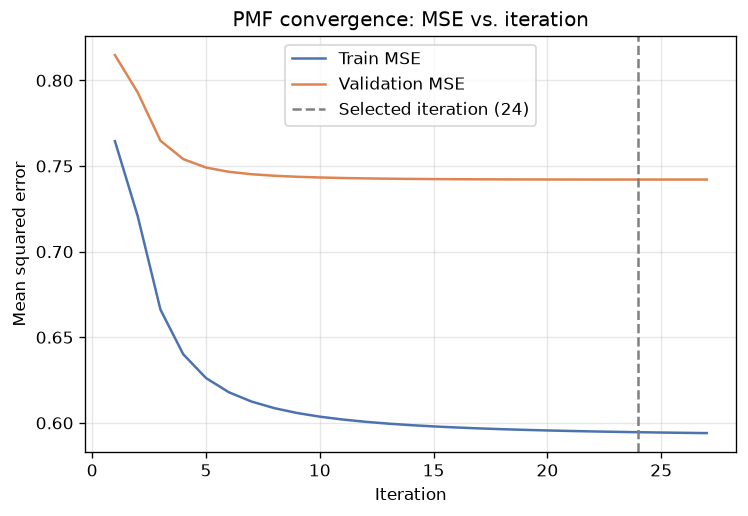

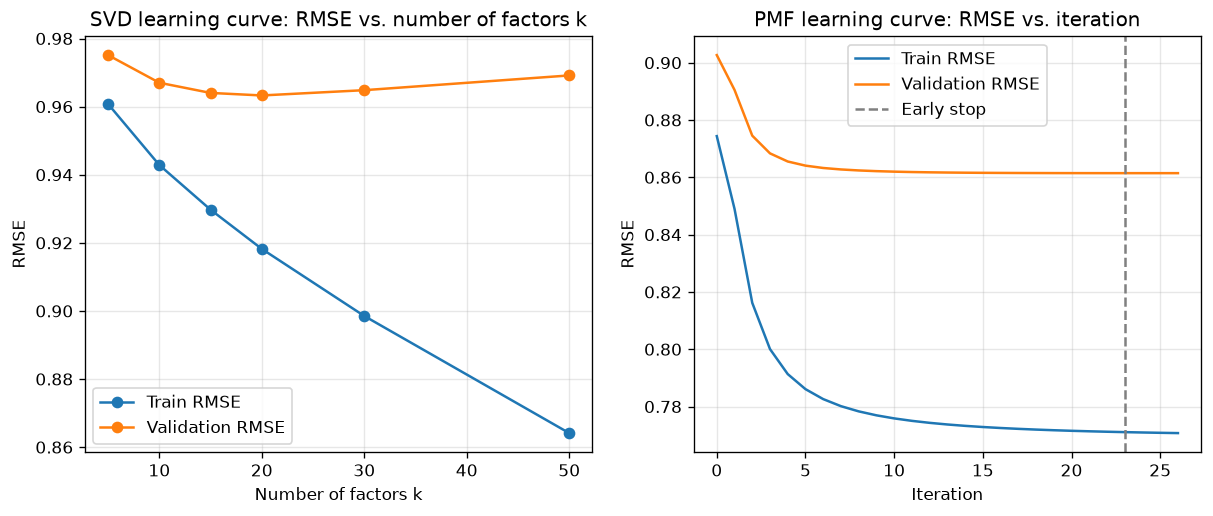

In [10]:
display(Image(str(reports / "pmf_convergence.png")))
display(Image(str(reports / "learning_curves.png")))

## 9. Interpretability

,factor,importance_pct,positive_pole,negative_pole,genre_positive,genre_negative
0,5,3.73,How Stella Got Her Groove Back (1998); Sliver ...,"Original Kings of Comedy, The (2000); Requiem ...",Horror,Documentary
1,2,3.34,Man Bites Dog (C'est arrivé près de chez vous)...,Idle Hands (1999); Tales from the Crypt Presen...,Musical,Horror
2,25,3.29,Friday the 13th Part V: A New Beginning (1985)...,"Mummy, The (1932); Crucible, The (1996); Pink ...",Action,Film-Noir
3,24,3.22,Paris Is Burning (1990); Hamlet (2000); Orland...,Blues Brothers 2000 (1998); Texas Chainsaw Mas...,Documentary,Children's
4,4,3.04,Orgazmo (1997); BASEketball (1998); Beavis and...,"East-West (Est-ouest) (1999); Big Kahuna, The ...",Horror,Children's
5,1,2.92,Lifeforce (1985); Bed of Roses (1996); Road to...,"Big Lebowski, The (1998); Bringing Out the Dea...",Children's,Film-Noir
6,14,2.90,"Way of the Gun, The (2000); Pitch Black (2000)...","Gay Divorcee, The (1934); Condorman (1981); He...",Thriller,Children's
7,28,2.86,"Mission to Mars (2000); Out-of-Towners, The (1...",Snow White and the Seven Dwarfs (1937); Robin ...,Thriller,Animation


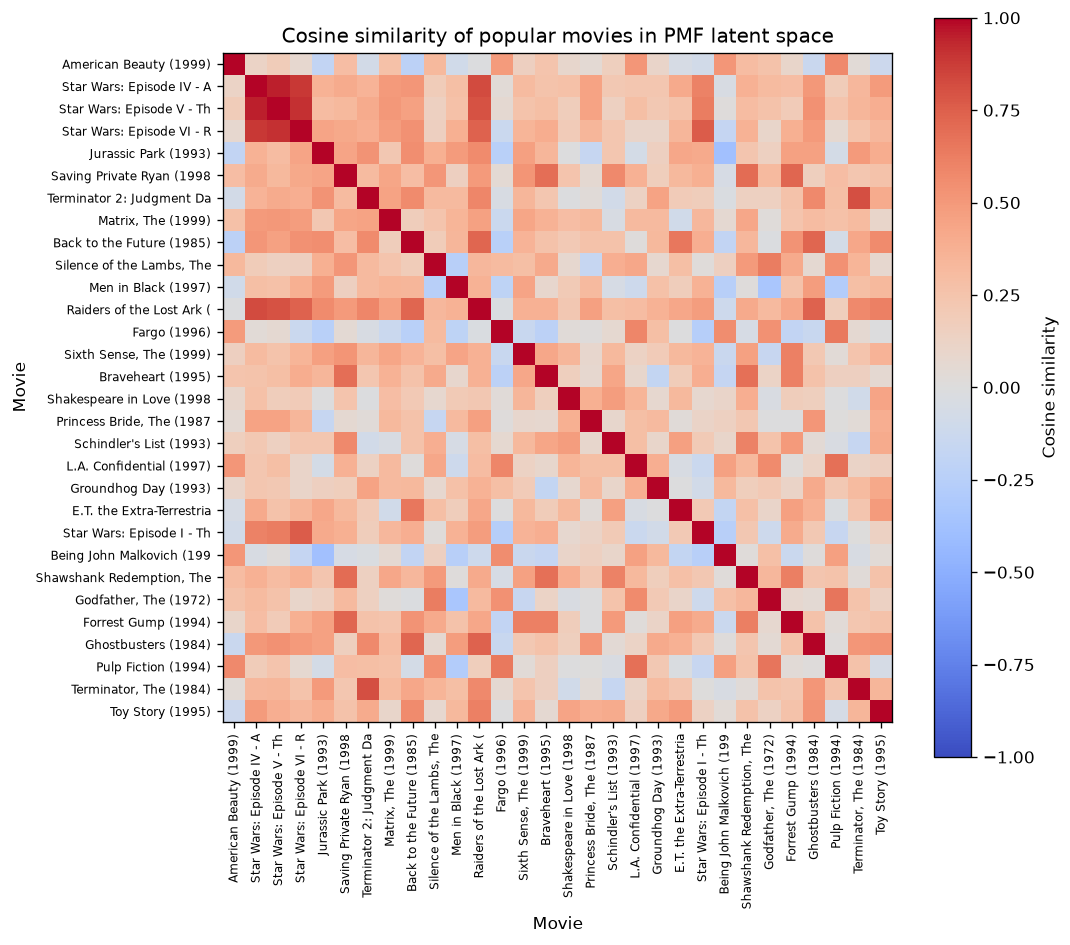

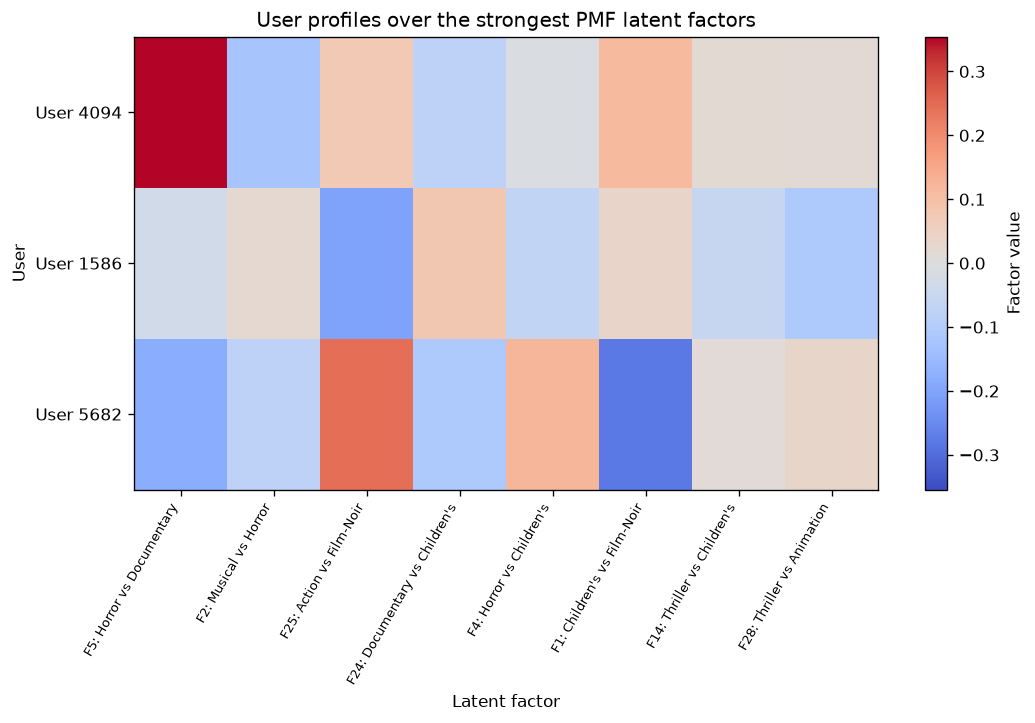

In [11]:
display(pd.read_csv(reports / "latent_factors.csv").head(8))
display(Image(str(reports / "item_similarity.png")))
display(Image(str(reports / "user_factors.png")))

# User-level analysis

- Training-set user 4094: train RMSE (PMF) 0.707, test RMSE (PMF) 0.682, test RMSE (SVD) 0.757, precision@10 vs held-out likes 0.00
- Training-set user 1586: train RMSE (PMF) 0.633, test RMSE (PMF) 0.604, test RMSE (SVD) 0.655, precision@10 vs held-out likes 0.20
- Test-set user 5682: train RMSE (PMF) 0.874, test RMSE (PMF) 1.027, test RMSE (SVD) 1.053, precision@10 vs held-out likes 0.40

## Why recommendations were more accurate for user 1586 than for user 4094

- User 1586 has more training ratings (335 vs 203), giving the latent profile more evidence.
- User 1586 rates more consistently (std 0.78 vs 0.81), which is easier to predict.
- User 4094 concentrates on Comedy (20% vs 16%), so genre concentration does not explain the gap.

## Test-set user 5682

Evaluated only on held-out ratings (121 ratings): PMF RMSE 1.027, SVD RMSE 1.053.

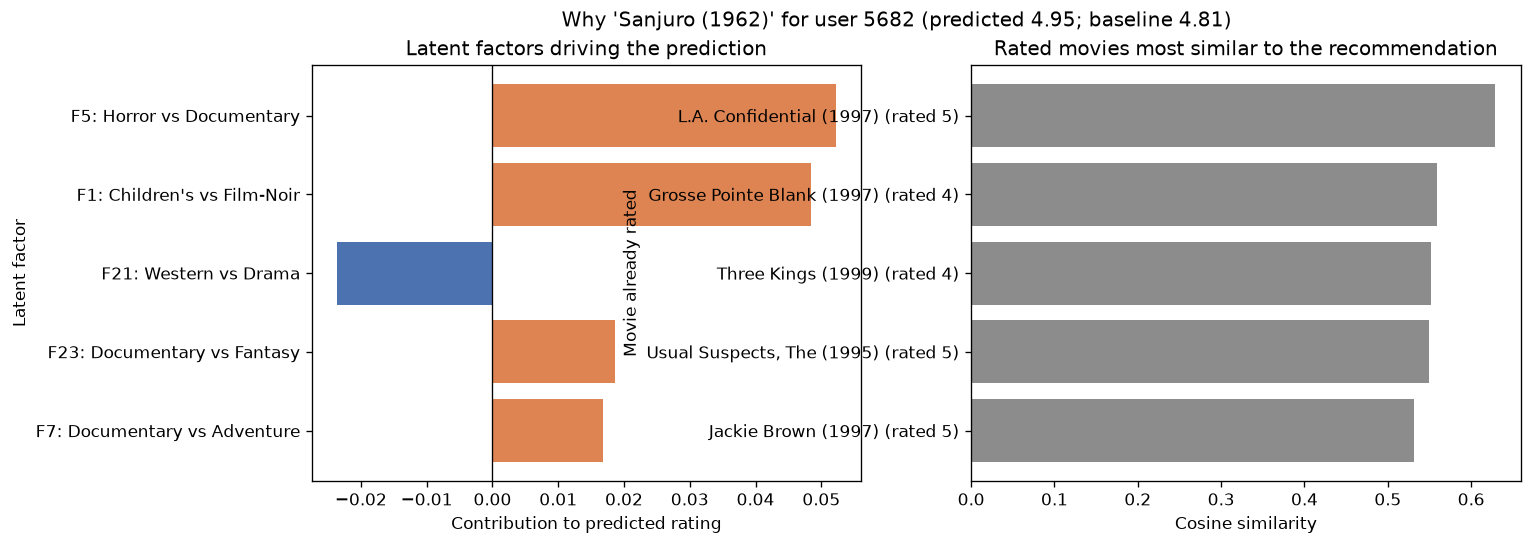

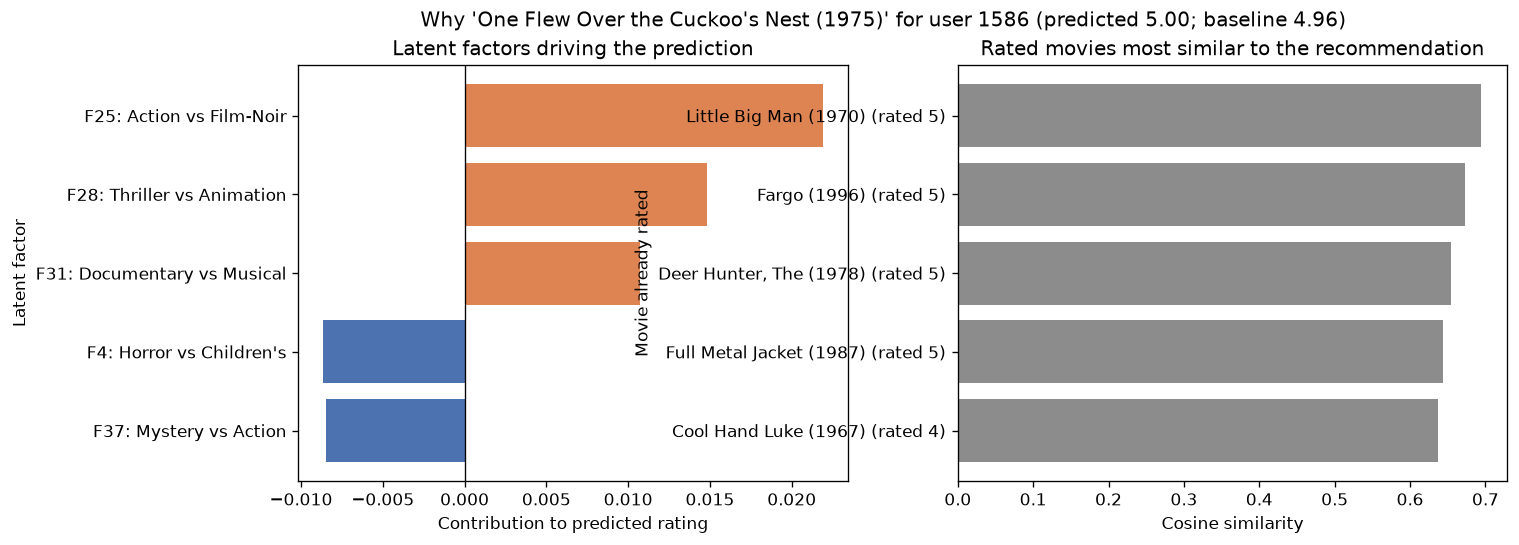

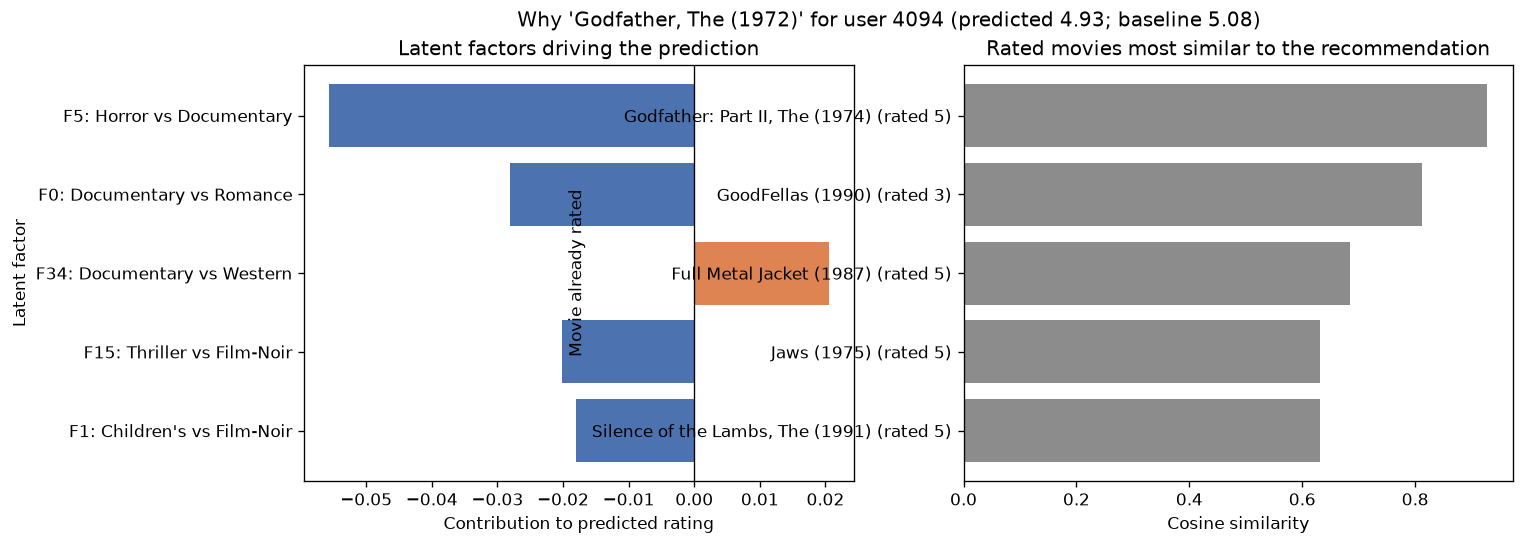

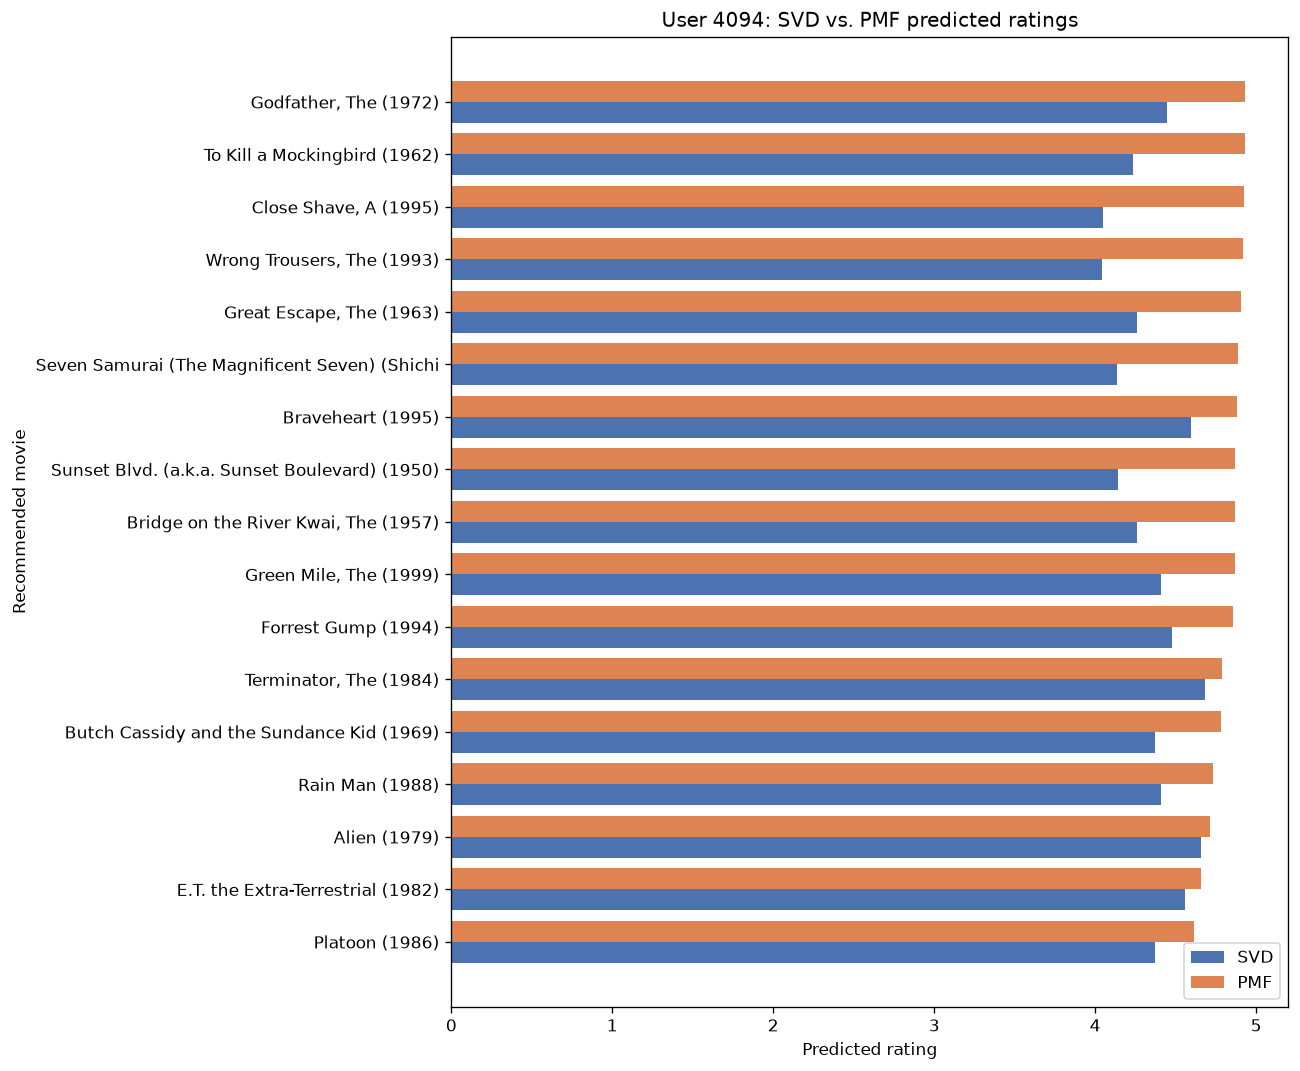

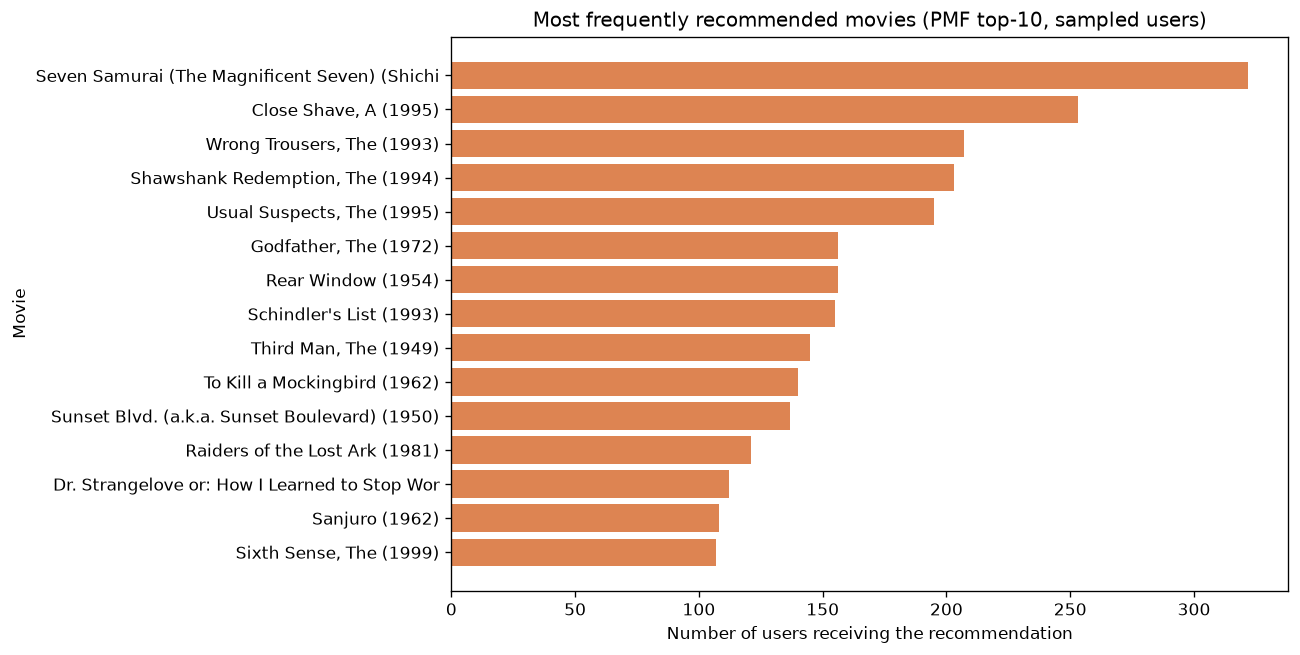

In [12]:
display(Markdown((reports / "user_analysis.md").read_text()))
user_ids_reported = [p.name.split("_")[1] for p in reports.glob("user_*_recommendations.csv")]
for uid in user_ids_reported:
    display(Image(str(reports / f"why_recommended_user_{uid}.png")))
display(Image(str(reports / "user_comparison.png")))
display(Image(str(reports / "top_recommendations.png")))

## 10. Recommendation demo

In [13]:
from utils.recommendation import generate_recommendations, user_top_rated

uid = int(user_ids_reported[0])
display(user_top_rated(uid, 5))
display(generate_recommendations(uid, "svd", 10))
display(generate_recommendations(uid, "pmf", 10))

,movie_id,title,genres,rating
0,527,Schindler's List (1993),Drama|War,5.0
1,1246,Dead Poets Society (1989),Drama,5.0
2,991,Michael Collins (1996),Drama|War,5.0
3,2231,Rounders (1998),Crime|Drama,5.0
4,1198,Raiders of the Lost Ark (1981),Action|Adventure,5.0


,rank,movie_id,title,genres,predicted_rating
0,1,3253,Wayne's World (1992),Comedy,4.301
1,2,3386,JFK (1991),Drama|Mystery,4.240
2,3,3408,Erin Brockovich (2000),Drama,4.208
3,4,1954,Rocky (1976),Action|Drama,4.174
4,5,1060,Swingers (1996),Comedy|Drama,4.157
5,6,3448,"Good Morning, Vietnam (1987)",Comedy|Drama|War,4.151
6,7,2795,Vacation (1983),Comedy,4.150
7,8,2355,"Bug's Life, A (1998)",Animation|Children's|Comedy,4.132
8,9,2671,Notting Hill (1999),Comedy|Romance,4.110
9,10,3006,"Insider, The (1999)",Drama,4.089


,rank,movie_id,title,genres,predicted_rating
0,1,2905,Sanjuro (1962),Action|Adventure,4.946
1,2,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama,4.939
2,3,904,Rear Window (1954),Mystery|Thriller,4.896
3,4,1262,"Great Escape, The (1963)",Adventure|War,4.854
4,5,2019,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,4.840
5,6,745,"Close Shave, A (1995)",Animation|Comedy|Thriller,4.827
6,7,908,North by Northwest (1959),Drama|Thriller,4.785
7,8,1212,"Third Man, The (1949)",Mystery|Thriller,4.773
8,9,1136,Monty Python and the Holy Grail (1974),Comedy,4.770
9,10,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),Film-Noir,4.764
